In [21]:
import pandas as pd
import geopandas as gpd

df = pd.read_csv("./data/bdc_37_fixed_broadband_served_unserved_J26_24oct2026.csv")
county_geoids_df = pd.read_csv("./data/ncstate_county_geoids.csv")

In [22]:
df = df.astype({"location_id": str,"block_geoid": str, "any_dl100_ul20": bool, "wired_dl100_ul20": bool, "terrestrial_dl100_ul20": bool})

In [23]:
df["County GEOID"] = df["block_geoid"].str[2:5]
df["Census Tract GEOID"] = df["block_geoid"].str[5:11]

In [24]:
clean_df = df[["County GEOID", "Census Tract GEOID", "any_dl100_ul20", "wired_dl100_ul20", "terrestrial_dl100_ul20"]]

In [25]:
county_geoids_df = county_geoids_df.astype({"FIPS Code": str})
county_geoids_df["FIPS Code"] = county_geoids_df["FIPS Code"].str[2:]
county_geoids_df["County"] = county_geoids_df["County"].str.replace(" County", "").str.strip()

In [26]:
county_geoids_df.head()

,County,FIPS Code,Tracts
0,Alamance,001,36
1,Alexander,003,7
2,Alleghany,005,3
3,Anson,007,6
4,Ashe,009,6


In [27]:
clean_df.head()

,County GEOID,Census Tract GEOID,any_dl100_ul20,wired_dl100_ul20,terrestrial_dl100_ul20
0,171,930301,True,False,True
1,189,920800,True,True,True
2,189,920900,True,True,True
3,189,920702,True,True,True
4,189,920200,True,True,True


In [28]:
merged_df = pd.merge(clean_df, county_geoids_df[["County", "FIPS Code"]], left_on="County GEOID", right_on="FIPS Code", how="left")
county_col = merged_df.pop("County")
merged_df = merged_df.drop(columns=["County GEOID", "FIPS Code"])
merged_df.insert(0, "County", county_col)

In [29]:
merged_df.head()

,County,Census Tract GEOID,any_dl100_ul20,wired_dl100_ul20,terrestrial_dl100_ul20
0,Surry,930301,True,False,True
1,Watauga,920800,True,True,True
2,Watauga,920900,True,True,True
3,Watauga,920702,True,True,True
4,Watauga,920200,True,True,True


In [30]:
merged_df["no_terra_service"] = merged_df["terrestrial_dl100_ul20"] == False

threshold = 15

In [31]:
by_county = merged_df.groupby("County")["no_terra_service"].agg(["size","sum","mean"])
by_county = by_county.sort_values(by="mean", ascending=False)
by_county["% Without Coverage"] = round(by_county["mean"] * 100,2)
by_county = by_county.rename(columns={"size": "Total Locations", "sum": "No Terrestrial Service"})
by_county = by_county[by_county["Total Locations"] >= 100]
by_county = by_county[by_county["% Without Coverage"] >= 15]
by_county = by_county.drop(columns="mean")
by_county.head()

,Total Locations,No Terrestrial Service,% Without Coverage
County,,,
Graham,5507,2401,43.60
Swain,10399,4292,41.27
Clay,8106,2646,32.64
Jackson,25809,7274,28.18
Hyde,3824,1076,28.14


In [32]:
by_tract = merged_df.groupby(["County", "Census Tract GEOID"])["no_terra_service"].agg(["size","sum","mean"])
by_tract = by_tract.sort_values(by="mean", ascending=False)
by_tract["% Without Coverage"] = round(by_tract["mean"] * 100,2)
by_tract = by_tract.rename(columns={"size": "Total Locations", "sum": "No Terrestrial Service"})
by_tract = by_tract.drop(columns="mean")
by_tract = by_tract[by_tract["Total Locations"] >= 100]
by_tract = by_tract[by_tract["% Without Coverage"] >= threshold]
print(len(by_tract))
by_tract.head()

120


Total Locations  No Terrestrial Service  \
County  Census Tract GEOID                                            
Jackson 950800                         2987                    2234   
        950700                         1911                    1427   
Swain   960301                         2807                    1995   
Graham  920100                         2057                    1460   
Clay    950102                         1973                    1162   

                            % Without Coverage  
County  Census Tract GEOID                      
Jackson 950800                           74.79  
        950700                           74.67  
Swain   960301                           71.07  
Graham  920100                           70.98  
Clay    950102                           58.90

In [35]:
by_county.to_excel(f"./results/PercentWithoutCoveragebyCountywithThreshold{threshold}.xlsx", index=True)
by_tract.to_excel(f"./results/PercentWithoutCoveragebyTractwithThreshold{threshold}.xlsx", index=True)

In [ ]:
shape_df = gpd.read_file("data/tl_2020_37_tract.zip")

2672


,STATEFP,COUNTYFP,TRACTCE,GEOID,NAME,NAMELSAD,MTFCC,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
0,37,141,920300,37141920300,9203,Census Tract 9203,G5020,S,236115472,605423,+34.6713171,-078.0020072,"POLYGON ((-78.15648 34.6791, -78.15458 34.6803..."
1,37,141,990100,37141990100,9901,Census Tract 9901,G5020,S,0,133298393,+34.3492469,-077.6031267,"POLYGON ((-77.71433 34.29117, -77.71406 34.291..."
2,37,071,031600,37071031600,316,Census Tract 316,G5020,S,22744042,66304,+35.2681382,-081.2849294,"POLYGON ((-81.3256 35.26363, -81.32556 35.2636..."
3,37,071,031800,37071031800,318,Census Tract 318,G5020,S,6071060,8149,+35.2623339,-081.2292201,"POLYGON ((-81.25719 35.26613, -81.25585 35.266..."
4,37,155,961801,37155961801,9618.01,Census Tract 9618.01,G5020,S,103973789,0,+34.6244596,-079.2476138,"POLYGON ((-79.31012 34.59978, -79.31002 34.599..."


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

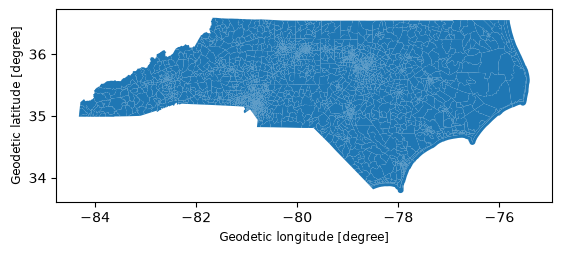

In [38]:
shape_df.plot()